<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and interpretation](README.md)

# 01 · Same proportions, different total counts

If one community has three times as many counts as an otherwise identical community, should their distance be zero? That depends on what the distance is intended to measure. We will compare within-sample diversity, raw Bray–Curtis distance and Bray–Curtis after closing each sample to proportions. SQL will independently reconstruct the worker's results.

**All six communities and five features are synthetic.** The counts below are deliberately constructed examples, not sequencing data, species observations or evidence of a biological effect. A uniform count multiplier isolates an arithmetic property; real deeper sampling can also discover features or change estimated proportions. This example does not simulate that sampling process.

## Change the scale of one sample

`DEPTH_MULTIPLIER` is an integer from **1 to 20**, default **3**. It multiplies every count of `B_scaled`, whose baseline composition exactly matches `A_base`. Every other row stays fixed. The end experiment uses **8**. These are dimensionless count multipliers, not elapsed time or biological replication.

Restart Kernel → Run All after editing. The locked notebook environment and literal worker launch work from this directory alone.

In [1]:
DEPTH_MULTIPLIER = 3  # Multiply B_scaled counts uniformly; experiment: 8

In [2]:
import hashlib
import json
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display

assert type(DEPTH_MULTIPLIER) is int and 1 <= DEPTH_MULTIPLIER <= 20
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        "Six synthetic communities · five arbitrary features · real scikit-bio worker · no biological inference",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.07, 1, 0.94))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-scikit-bio/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-scikit-bio/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-scikit-bio/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-scikit-bio/notebooks/pyproject.toml.

## Make the input and worker connection explicit

The tagged Git release is fetched by `uvx`; `worker-constraints.txt` fixes the tested scientific and protocol dependencies. No repository source or local worker binary is required.

Each sample has exactly one row for each feature, including **explicit zeros**. A zero means absence in this constructed table, not a missing measurement. The worker pivots long input, sums duplicate keys and treats missing/NULL cells as zero for beta diversity and closure; we reject duplicates and NULLs before using those operations. All totals are positive. This avoids confusing an unavailable sample with an empty community.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'skbio' (
 TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-scikit-bio.git@v0.3.0 --constraints worker-constraints.txt vgi-scikit-bio'
);
CREATE TABLE base_counts AS
SELECT sample_id, 'F' || feature_number::VARCHAR AS feature_id, abundance::BIGINT AS abundance
FROM (VALUES
 ('A_base',   [50,30,15,5,0]),
 ('B_scaled', [50,30,15,5,0]),
 ('C_even',   [20,20,20,20,20]),
 ('D_dominant',[90,5,3,2,0]),
 ('E_reversed',[0,5,15,30,50]),
 ('F_mixed',  [10,10,30,30,20])
) AS v(sample_id, counts), UNNEST(counts) WITH ORDINALITY AS u(abundance,feature_number);
CREATE TABLE counts AS
SELECT sample_id,feature_id,
 abundance * CASE WHEN sample_id='B_scaled' THEN {{DEPTH_MULTIPLIER}} ELSE 1 END AS abundance
FROM base_counts;
SELECT sample_id, sum(abundance) AS total_counts,
 count(*) AS explicit_feature_rows, count(*) FILTER(WHERE abundance=0) AS explicit_zeros
FROM counts GROUP BY sample_id ORDER BY sample_id;

,sample_id,total_counts,explicit_feature_rows,explicit_zeros
0,A_base,100.0,5,1
1,B_scaled,300.0,5,1
2,C_even,100.0,5,0
3,D_dominant,100.0,5,1
4,E_reversed,100.0,5,1
5,F_mixed,100.0,5,0


In [4]:
raw = con.execute("SELECT * FROM counts ORDER BY sample_id,feature_id").df()
base = con.execute("SELECT * FROM base_counts ORDER BY sample_id,feature_id").fetchall()
base_fingerprint = hashlib.sha256(json.dumps(base).encode()).hexdigest()
assert not raw.isna().any().any() and not raw.duplicated(["sample_id", "feature_id"]).any()
assert (raw.abundance >= 0).all() and (raw.abundance % 1 == 0).all()
assert raw.groupby("sample_id").abundance.sum().gt(0).all()
assert raw.groupby("sample_id").feature_id.nunique().eq(raw.feature_id.nunique()).all()
prose(
    f"The input has **{raw.sample_id.nunique()} samples × {raw.feature_id.nunique()} features**, all explicit. Only B_scaled changes: its total is **{raw.loc[raw.sample_id == 'B_scaled', 'abundance'].sum():,} counts**, versus **{raw.loc[raw.sample_id == 'A_base', 'abundance'].sum():,}** for A_base. The fixed baseline fingerprint is `{base_fingerprint}`."
)

The input has **6 samples × 5 features**, all explicit. Only B_scaled changes: its total is **300 counts**, versus **100** for A_base. The fixed baseline fingerprint is `ebbdb413287057d0d108b3e7e3d8fb0be324b8275a07d5661446cf4dee23c242`.

## Within-sample diversity ignores a uniform multiplier

Compute observed richness (positive features), Shannon entropy and the Hill number of order 1. Shannon uses natural logarithms, so its units are **nats**; `exp(H)` expresses the same diversity as an **effective number of equally abundant features**. The worker's alpha aggregates round inputs to integers and skip NULLs, so we pass only the validated integer counts—not proportions.

These summaries do not retain feature identity. `E_reversed` has A's count values assigned to different features, so it can share the same diversity without sharing composition. [scikit-bio Shannon documentation](https://scikit.bio/docs/latest/generated/skbio.diversity.alpha.shannon.html).

In [5]:
%%sql
CREATE TABLE alpha_worker AS
SELECT sample_id,skbio.diversity.observed_features(abundance) AS richness,
 skbio.diversity.shannon(abundance) AS shannon_nats,
 skbio.diversity.hill(abundance,1) AS effective_features
FROM counts GROUP BY sample_id;
CREATE TABLE proportions AS
SELECT * FROM skbio.stats.closure(
 (SELECT sample_id,feature_id,abundance FROM counts ORDER BY sample_id,feature_id), pseudocount := 0);
CREATE TABLE alpha_sql AS
SELECT sample_id,count(*) FILTER(WHERE proportion>0) AS richness,
 -sum(CASE WHEN proportion>0 THEN proportion*ln(proportion) ELSE 0 END) AS shannon_nats
FROM proportions GROUP BY sample_id;

,Count


In [6]:
%%sql alpha <<
SELECT w.sample_id,t.total_counts,w.richness,w.shannon_nats,w.effective_features,
 abs(w.shannon_nats-s.shannon_nats) AS entropy_reconstruction_error
FROM alpha_worker w JOIN alpha_sql s USING(sample_id)
JOIN (SELECT sample_id,sum(abundance) AS total_counts FROM counts GROUP BY sample_id) t USING(sample_id)
ORDER BY sample_id;

,sample_id,total_counts,richness,shannon_nats,effective_features,entropy_reconstruction_error
0,A_base,100.0,4.0,1.142120,3.133404,0.0
1,B_scaled,300.0,4.0,1.142120,3.133404,0.0
2,C_even,100.0,5.0,1.609438,5.000000,0.0
3,D_dominant,100.0,4.0,0.428048,1.534260,0.0
4,E_reversed,100.0,4.0,1.142120,3.133404,0.0
5,F_mixed,100.0,5.0,1.504788,4.503200,0.0


A_base and B_scaled both have **4 observed features**, **1.1421 nats** and **3.133 effective features**, despite the **3×** total-count difference. E_reversed also has **3.133 effective features**. The next step will expose which feature identities these summaries leave out.

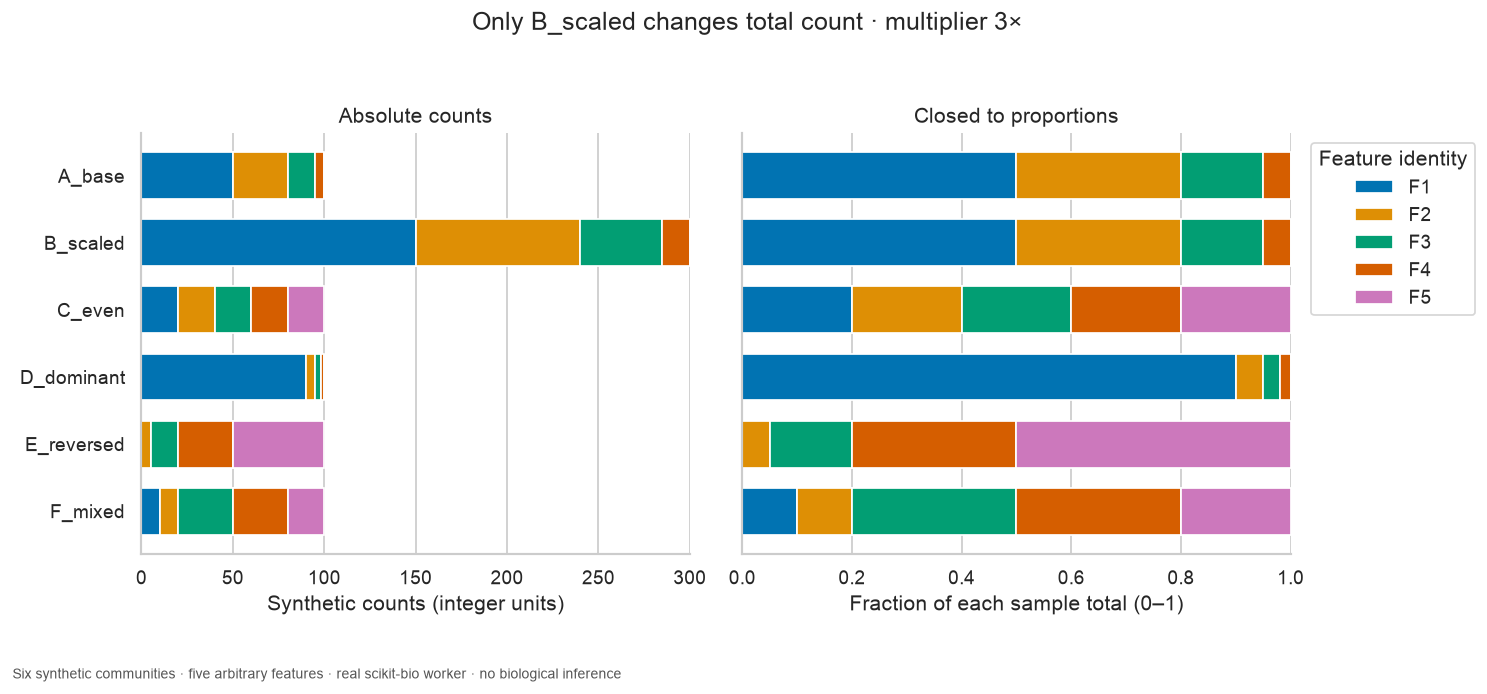

In [7]:
display(alpha.round(6))
assert np.isfinite(alpha.select_dtypes("number")).all().all()
assert np.allclose(alpha.shannon_nats, np.log(alpha.effective_features), atol=1e-12)
assert alpha.entropy_reconstruction_error.max() < 1e-12
assert (alpha.effective_features >= 1 - 1e-12).all() and (
    alpha.effective_features <= alpha.richness + 1e-12
).all()
a = alpha.set_index("sample_id")
assert np.allclose(
    a.loc["A_base", ["richness", "shannon_nats", "effective_features"]].astype(float),
    a.loc["B_scaled", ["richness", "shannon_nats", "effective_features"]].astype(float),
)
props = con.execute("SELECT * FROM proportions ORDER BY sample_id,feature_id").df()
assert len(props) == len(raw) and np.isfinite(props.proportion).all()
assert np.allclose(props.groupby("sample_id").proportion.sum(), 1)
assert (
    con.execute(
        "SELECT max(abs(p.proportion-c.abundance/t.total)) FROM proportions p JOIN counts c USING(sample_id,feature_id) JOIN (SELECT sample_id,sum(abundance) AS total FROM counts GROUP BY sample_id) t USING(sample_id)"
    ).fetchone()[0]
    < 1e-12
)
prose(
    f"A_base and B_scaled both have **{a.loc['A_base', 'richness']:.0f} observed features**, **{a.loc['A_base', 'shannon_nats']:.4f} nats** and **{a.loc['A_base', 'effective_features']:.3f} effective features**, despite the **{DEPTH_MULTIPLIER}×** total-count difference. E_reversed also has **{a.loc['E_reversed', 'effective_features']:.3f} effective features**. The next step will expose which feature identities these summaries leave out."
)
order = list(a.index)
features = sorted(raw.feature_id.unique())
colors = sns.color_palette("colorblind", len(features))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, data, value, title in [
    (axes[0], raw, "abundance", "Absolute counts"),
    (axes[1], props, "proportion", "Closed to proportions"),
]:
    matrix = data.pivot(index="sample_id", columns="feature_id", values=value).reindex(
        index=order, columns=features
    )
    left = np.zeros(len(order))
    for feature, color in zip(features, colors, strict=True):
        values = matrix[feature].to_numpy()
        ax.barh(order, values, left=left, color=color, label=feature, height=0.7)
        left += values
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
axes[0].invert_yaxis()
axes[0].set_xlabel("Synthetic counts (integer units)")
axes[1].set_xlabel("Fraction of each sample total (0–1)")
axes[1].set_xlim(0, 1)
axes[1].legend(title="Feature identity", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle(f"Only B_scaled changes total count · multiplier {DEPTH_MULTIPLIER}×")
finish(fig)

## Between-sample distance depends on the chosen scale

For nonnegative vectors with a positive combined total, Bray–Curtis is **`sum(abs(x-y)) / sum(x+y)`**. Its raw-count value can change when just one sample is multiplied. For identical compositions scaled by `k`, the distance is **`abs(k-1)/(k+1)`**.

Closing each row divides by its own total. On the resulting proportions, Bray–Curtis equals **half the L1 difference**, because the denominator is two. This removes total-count scale; it does not recover absolute abundance, correct sampling uncertainty, or make zeros into measurements. No pseudocount is added. [SciPy Bray–Curtis definition](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.braycurtis.html).

Materialize the two full square matrices once, then compare each unordered pair. The SQL reconstruction uses the original counts and worker proportions independently for every pair.

In [8]:
%%sql
CREATE TABLE raw_distances AS
SELECT * FROM skbio.diversity.beta_diversity(
 (SELECT sample_id,feature_id,abundance FROM counts ORDER BY sample_id,feature_id), metric := 'braycurtis');
CREATE TABLE relative_distances AS
SELECT * FROM skbio.diversity.beta_diversity(
 (SELECT sample_id,feature_id,proportion FROM proportions ORDER BY sample_id,feature_id), metric := 'braycurtis');
CREATE TABLE sql_distances AS
SELECT a.sample_id AS id_1,b.sample_id AS id_2,
 sum(abs(a.abundance-b.abundance))/sum(a.abundance+b.abundance) AS raw_bc,
 sum(abs(p.proportion-q.proportion))/2 AS relative_bc
FROM counts a JOIN counts b USING(feature_id)
JOIN proportions p ON p.sample_id=a.sample_id AND p.feature_id=a.feature_id
JOIN proportions q ON q.sample_id=b.sample_id AND q.feature_id=b.feature_id
GROUP BY a.sample_id,b.sample_id;
CREATE TABLE distance_comparison AS
SELECT r.id_1,r.id_2,r.distance AS raw_bc,p.distance AS relative_bc,
 abs(r.distance-s.raw_bc) AS raw_error,abs(p.distance-s.relative_bc) AS relative_error
FROM raw_distances r JOIN relative_distances p USING(id_1,id_2)
JOIN sql_distances s USING(id_1,id_2);

,Count


In [9]:
%%sql pairs <<
SELECT id_1,id_2,raw_bc,relative_bc,raw_bc-relative_bc AS raw_minus_relative
FROM distance_comparison WHERE id_1 < id_2 ORDER BY id_1,id_2;

In [10]:
%%sql checks <<
SELECT 'full_square_unique_pairs' AS check_name,
 count(*)=count(DISTINCT (id_1,id_2)) AND count(*)=pow((SELECT count(DISTINCT sample_id) FROM counts),2) AS passed
FROM distance_comparison
UNION ALL SELECT 'finite_and_bounded',bool_and(isfinite(raw_bc) AND isfinite(relative_bc) AND raw_bc BETWEEN 0 AND 1 AND relative_bc BETWEEN 0 AND 1) FROM distance_comparison
UNION ALL SELECT 'zero_diagonal',bool_and(abs(raw_bc)<1e-12 AND abs(relative_bc)<1e-12) FROM distance_comparison WHERE id_1=id_2
UNION ALL SELECT 'symmetric',bool_and(abs(a.raw_bc-b.raw_bc)<1e-12 AND abs(a.relative_bc-b.relative_bc)<1e-12) FROM distance_comparison a JOIN distance_comparison b ON a.id_1=b.id_2 AND a.id_2=b.id_1
UNION ALL SELECT 'both_formula_reconstructions',bool_and(raw_error<1e-12 AND relative_error<1e-12) FROM distance_comparison
UNION ALL SELECT 'scaled_duplicate_formula',abs(raw_bc-abs({{DEPTH_MULTIPLIER}}-1.0)/({{DEPTH_MULTIPLIER}}+1))<1e-12 AND abs(relative_bc)<1e-12 FROM distance_comparison WHERE id_1='A_base' AND id_2='B_scaled';

,id_1,id_2,raw_bc,relative_bc,raw_minus_relative
0,A_base,B_scaled,0.500,0.00,0.500
1,A_base,C_even,0.400,0.40,-0.000
2,A_base,D_dominant,0.400,0.40,0.000
3,A_base,E_reversed,0.750,0.75,0.000
4,A_base,F_mixed,0.600,0.60,-0.000
5,B_scaled,C_even,0.625,0.40,0.225
6,B_scaled,D_dominant,0.500,0.40,0.100
7,B_scaled,E_reversed,0.825,0.75,0.075
8,B_scaled,F_mixed,0.675,0.60,0.075
9,C_even,D_dominant,0.700,0.70,0.000


,check_name,passed
0,full_square_unique_pairs,True
1,finite_and_bounded,True
2,zero_diagonal,True
3,symmetric,True
4,both_formula_reconstructions,True
5,scaled_duplicate_formula,True


The identical-composition pair A_base/B_scaled has raw Bray–Curtis **0.500000**, exactly **|3−1|/(3+1)**, but proportion-based distance **0.000000**. A_base/E_reversed have equal alpha diversity yet proportion-based distance **0.750**: feature identity matters. All **6 matrix checks** pass, including both full SQL reconstructions. Raw-minus-relative is a change in the question being asked, not an estimated correction for bias.

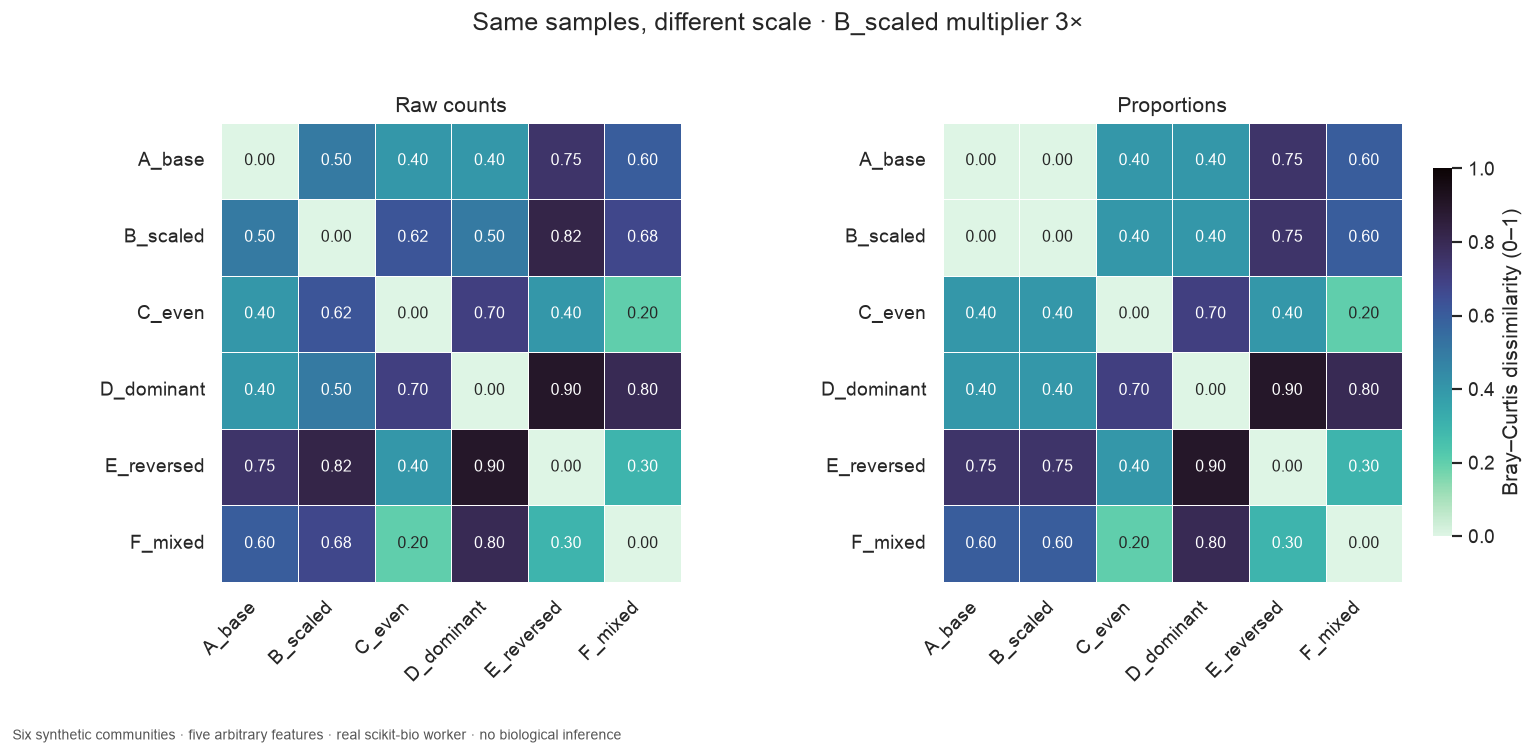

11175

In [11]:
display(pairs.round(6))
display(checks)
assert checks.passed.all()
focus = pairs.loc[(pairs.id_1 == "A_base") & (pairs.id_2 == "B_scaled")].iloc[0]
rev = pairs.loc[(pairs.id_1 == "A_base") & (pairs.id_2 == "E_reversed")].iloc[0]
prose(
    f"The identical-composition pair A_base/B_scaled has raw Bray–Curtis **{focus.raw_bc:.6f}**, exactly **|{DEPTH_MULTIPLIER}−1|/({DEPTH_MULTIPLIER}+1)**, but proportion-based distance **{focus.relative_bc:.6f}**. A_base/E_reversed have equal alpha diversity yet proportion-based distance **{rev.relative_bc:.3f}**: feature identity matters. All **{len(checks)} matrix checks** pass, including both full SQL reconstructions. Raw-minus-relative is a change in the question being asked, not an estimated correction for bias."
)
dm = con.execute("SELECT * FROM distance_comparison ORDER BY id_1,id_2").df()
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))
for ax, value, title in [(axes[0], "raw_bc", "Raw counts"), (axes[1], "relative_bc", "Proportions")]:
    matrix = dm.pivot(index="id_1", columns="id_2", values=value).reindex(index=order, columns=order)
    sns.heatmap(
        matrix,
        ax=ax,
        vmin=0,
        vmax=1,
        cmap="mako_r",
        annot=True,
        fmt=".2f",
        square=True,
        linewidths=0.5,
        cbar=value == "relative_bc",
        cbar_kws={"label": "Bray–Curtis dissimilarity (0–1)", "shrink": 0.8},
        annot_kws={"fontsize": 9},
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    for tick in ax.get_xticklabels():
        tick.set_horizontalalignment("right")
fig.suptitle(f"Same samples, different scale · B_scaled multiplier {DEPTH_MULTIPLIER}×")
finish(fig)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "multiplier": DEPTH_MULTIPLIER,
            "base_fingerprint": base_fingerprint,
            "alpha": alpha.to_dict(orient="records"),
            "proportions": props.to_dict(orient="records"),
            "distances": dm.to_dict(orient="records"),
            "checks": checks.to_dict(orient="records"),
        },
        indent=2,
    )
)

## Experiment: increase only the duplicate's count scale

Change `DEPTH_MULTIPLIER` from **3 to 8**. Predict A_base/B_scaled raw Bray–Curtis changing from **1/2 to 7/9**. Its proportion-based distance should stay zero. All alpha summaries, the entire proportion-based matrix and every raw pair that excludes B_scaled should remain unchanged; only B_scaled's raw-count comparisons can move.

Compare the count/proportion bars, A_base/B_scaled row and both heatmaps. They use the same feature colors and a fixed 0–1 distance scale across runs; the count axis follows the selected total. Restore **3** afterwards.

Closure is useful when the question is relative composition, and deliberately discards total size. It is not rarefaction or a sampling-depth adjustment. This deterministic example has no biological replicates, inferential test, confidence intervals or claim about unseen features. A distance matrix alone cannot establish ecological mechanism or group significance.

In [12]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)